# Frente de ML – teste em período nunca visto (abr–set/2026)

**Pergunta:** candles maiores com limiar alto tornam o Random Forest lucrativo depois dos custos?

As hipóteses foram registradas **antes** de rodar, em `resultados/ml/hipotese_abr_set_2026.json`:

| Hipótese | Candle | Janela | Limiar | TP / SL |
|---|---|---|---|---|
| H15 | 15 min | 12 meses | quantil 90% de \|previsão\| na validação 2024 | sem / sem |
| H60 | 60 min | 12 meses | quantil 90% de \|previsão\| na validação 2024 | sem / sem |

- **Período novo:** 01/04/2026 → 25/09/2026. A base comum do projeto termina em 01/04/2026 porque o WDO acaba ali; nenhum modelo viu esses meses.
- **Base só com WIN:** o Random Forest não usa o WDO. Para reaproveitar o `tt1_comum.py` sem alterá-lo, o WIN é passado também no lugar do WDO; as colunas `*_wdo` resultantes não entram nas features `COMPLETO`.
- **Critério de sucesso (fixado antes):** esperança > 0 com t ≥ 2 e fator de lucro > 1, com custo de 5 pts.
- Os dois resultados são reportados; nada é re-ajustado depois.

In [1]:
import os, sys, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

sys.path.append(PASTA)
import tt1_comum as t

SAIDA = f"{PASTA}/resultados/ml"
HIP = json.load(open(f"{SAIDA}/hipotese_abr_set_2026.json", encoding="utf-8"))
NOVO = ("2026-04-01", "2026-09-26")
FEATS = t.features()["COMPLETO"]

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
print("WIN vai até:", win.index.max())

WIN vai até: 2026-09-25 18:24:00


In [2]:
class FolhaProporcional:
    # mesmo modelo base da grade em frente_ml.ipynb: min_samples_leaf = max(10, 1% das linhas de treino)
    def __init__(self, estimador, folha_frac=0.01, folha_min=10):
        self.estimador, self.folha_frac, self.folha_min = estimador, folha_frac, folha_min
    def fit(self, X, y):
        self.min_leaf_ = max(self.folha_min, int(self.folha_frac * len(X)))
        self.m = clone(self.estimador).set_params(min_samples_leaf=self.min_leaf_).fit(X, y)
        return self
    def predict(self, X):
        return self.m.predict(X)

FABRICA = lambda: FolhaProporcional(RandomForestRegressor(n_estimators=100, max_depth=8, max_features=0.5,
                                                          n_jobs=-1, random_state=42))

def estat(ops):
    x = ops[ops.lado != 0].pontos
    if len(x) < 2:
        return dict(ep_pts=np.nan, t_stat=np.nan)
    ep = x.std() / np.sqrt(len(x))
    return dict(ep_pts=ep, t_stat=x.mean() / ep)

def clark_west(prev, lags=10):
    y, f = prev.y_true.values, prev.y_pred.values
    adj = y ** 2 - ((y - f) ** 2 - f ** 2)
    d, n = adj - adj.mean(), len(adj)
    s2 = d @ d / n + sum(2 * (1 - l / (lags + 1)) * (d[l:] @ d[:-l]) / n for l in range(1, lags + 1))
    return adj.mean() / np.sqrt(s2 / n)

def aleatorio_mesmos_candles(prev, seed=42):
    # direção sorteada, mas com o mesmo |previsão|: o limiar seleciona exatamente os mesmos candles do modelo
    rng = np.random.default_rng(seed)
    return prev.assign(y_pred=np.abs(prev.y_pred) * rng.choice([-1.0, 1.0], size=len(prev)))

In [3]:
linhas, curvas = [], {}
for h in HIP["hipoteses"]:
    candle, janela = h["candle"], h["janela_meses"]
    df, s = t.montar_base(win, win, candle)                     # base só com WIN
    prev_val = pd.read_csv(f"{SAIDA}/previsoes/WIN_{candle}_{janela}m_rf_val.csv", index_col=0, parse_dates=True)
    limiar = t.limiar_por_quantil(prev_val, 0.9)                 # fixado com a validação 2024
    prev = t.walk_forward(df, FEATS, FABRICA, *NOVO, janela_meses=janela)
    prev.to_csv(f"{SAIDA}/previsoes/WIN_{candle}_{janela}m_rf_abr_set_2026.csv")
    aleat = aleatorio_mesmos_candles(prev)
    for custo in t.CUSTOS_PTS:
        for serie, p in [("modelo", prev), ("aleatorio_mesmos_candles", aleat)]:
            ops = t.simular(p, limiar, None, None, custo)
            linhas.append(dict(hipotese=h["id"], candle=candle, janela_meses=janela, serie=serie, custo_pts=custo,
                               limiar_pct=limiar, limiar_pts_medio=limiar / 100 * prev.close.mean(),
                               candles=len(prev), mov_medio_pts=(prev.close_prox - prev.close).abs().mean(),
                               **(dict(**t.metricas(prev), cw_t=clark_west(prev)) if serie == "modelo" else {}),
                               **t.resumo_operacoes(ops), **estat(ops)))
            if custo == 5:
                curvas[(h["id"], serie)] = ops.pontos.cumsum() * t.PONTO_WIN

res = pd.DataFrame(linhas)
res["sucesso"] = (res.serie == "modelo") & (res.custo_pts == 5) & (res.esperanca_pts > 0) & (res.t_stat >= 2) & (res.fator_lucro > 1)
res.to_csv(f"{SAIDA}/resultado_abr_set_2026.csv", index=False)
res[["hipotese", "serie", "custo_pts", "candles", "mov_medio_pts", "limiar_pts_medio", "TheilU", "cw_t", "n_ops",
     "taxa_acerto", "payoff", "esperanca_pts", "ep_pts", "t_stat", "fator_lucro", "resultado_R", "sucesso"]].round(3)

,hipotese,serie,custo_pts,candles,mov_medio_pts,limiar_pts_medio,TheilU,cw_t,n_ops,taxa_acerto,payoff,esperanca_pts,ep_pts,t_stat,fator_lucro,resultado_R,sucesso
0,H15,modelo,0,4537,191.315,25.399,1.003,-1.751,460,0.485,0.941,-17.217,19.601,-0.878,0.893,-1584.0,False
1,H15,aleatorio_mesmos_candles,0,4537,191.315,25.399,NaN,NaN,460,0.522,0.994,13.783,19.607,0.703,1.095,1268.0,False
2,H15,modelo,5,4537,191.315,25.399,1.003,-1.751,460,0.476,0.935,-22.217,19.601,-1.133,0.864,-2044.0,False
3,H15,aleatorio_mesmos_candles,5,4537,191.315,25.399,NaN,NaN,460,0.520,0.975,8.783,19.607,0.448,1.059,808.0,False
4,H15,modelo,10,4537,191.315,25.399,1.003,-1.751,460,0.472,0.929,-27.217,19.601,-1.389,0.836,-2504.0,False
5,H15,aleatorio_mesmos_candles,10,4537,191.315,25.399,NaN,NaN,460,0.509,0.968,3.783,19.607,0.193,1.025,348.0,False
6,H60,modelo,0,1104,361.019,94.555,1.014,-1.586,120,0.483,0.738,-104.458,73.455,-1.422,0.691,-2507.0,False
7,H60,aleatorio_mesmos_candles,0,1104,361.019,94.555,NaN,NaN,120,0.550,0.883,21.625,74.050,0.292,1.079,519.0,False
8,H60,modelo,5,1104,361.019,94.555,1.014,-1.586,120,0.458,0.765,-109.458,73.455,-1.490,0.678,-2627.0,False
9,H60,aleatorio_mesmos_candles,5,1104,361.019,94.555,NaN,NaN,120,0.525,0.909,16.625,74.050,0.225,1.060,399.0,False


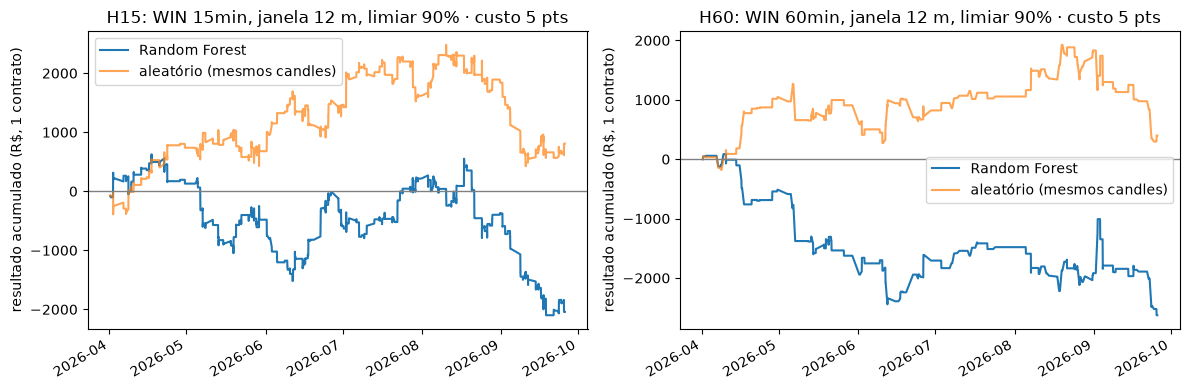

H15: 460 operações | esperança -22.22 pts/op (t = -1.13) | fator de lucro 0.86 | R$ -2,044 | critério de sucesso: não atingido
H60: 120 operações | esperança -109.46 pts/op (t = -1.49) | fator de lucro 0.68 | R$ -2,627 | critério de sucesso: não atingido


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, h in zip(axes, HIP["hipoteses"]):
    for serie, rot in [("modelo", "Random Forest"), ("aleatorio_mesmos_candles", "aleatório (mesmos candles)")]:
        curvas[(h["id"], serie)].plot(ax=ax, label=rot, alpha=1 if serie == "modelo" else 0.7)
    ax.axhline(0, color="gray", lw=1)
    ax.set_title(f"{h['id']}: WIN {h['candle']}, janela {h['janela_meses']} m, limiar 90% · custo 5 pts")
    ax.set_ylabel("resultado acumulado (R$, 1 contrato)"); ax.set_xlabel(""); ax.legend()
fig.tight_layout(); fig.savefig(f"{SAIDA}/curva_capital_abr_set_2026.png", dpi=150); plt.show()

for h in HIP["hipoteses"]:
    r = res[(res.hipotese == h["id"]) & (res.serie == "modelo") & (res.custo_pts == 5)].iloc[0]
    print(f"{h['id']}: {int(r.n_ops)} operações | esperança {r.esperanca_pts:.2f} pts/op (t = {r.t_stat:.2f}) | "
          f"fator de lucro {r.fator_lucro:.2f} | R$ {r.resultado_R:,.0f} | critério de sucesso: {'atingido' if r.sucesso else 'não atingido'}")